# PS2 evaluation: ROC, accuracy, and related metrics

Scores are compared with the account split in `Dataset/data/shared/splits.csv`: **train 1,680**, **validation 360**, **test 360**. Every account stays in one split. Models are fit on train accounts only. The threshold used for accuracy is chosen on validation and then applied to test.

Three checks:

1. **Next-dial right-party contact.** Each dial is scored from history strictly before that dial. The label is whether that dial was an RPC.
2. **Borrower-number detection.** The hidden Markov probability that the number belongs to the borrower, against the 250 verified phones. Labels were collected on 2 July 2026, after the call logs end.
3. **Payment within 14 days of an RPC.** The account repayment probability, on accounts whose 14-day window is complete.

Accuracy is reported next to the majority-class baseline. About 84% of dials are not an RPC, so a model that never predicts RPC already has accuracy near 0.84. ROC AUC and balanced accuracy are the numbers that show whether the score ranks the positive cases first.

## 1. Setup

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, confusion_matrix, f1_score, log_loss, precision_score,
    recall_score, roc_auc_score, roc_curve,
)
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
DECAY_LAMBDA = 0.05
PRIOR_STRENGTH = 4.0

ROOT = Path.cwd()
if not (ROOT / "Dataset").exists():
    ROOT = Path("/Users/nischayrangwani/OPEN_IIT_PS2")
DATA = ROOT / "Dataset" / "data"
OUT = ROOT / "outputs"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def display(obj):
    print(obj.to_string() if hasattr(obj, "to_string") else obj)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
print("splits file:", DATA / "shared" / "splits.csv")

splits file: /Users/adityagupta/Documents/OPEN_IIT/OPEN_IIT_PS2/Dataset/data/shared/splits.csv


## 2. Load the split and the scored tables

`splits.csv` is the only split used. Attempt labels come from the dial file built in `modelling.ipynb`. Phone posteriors come from `contact_point_scores.csv`.

In [4]:
splits = pd.read_csv(DATA / "shared" / "splits.csv")
print(splits["split"].value_counts().rename("accounts"))
assert splits["account_id"].is_unique
assert set(splits["split"]) == {"train", "validation", "test"}

dials = pd.read_csv(OUT / "dial_attempts_with_ptp.csv", parse_dates=["attempt_ts"])
phones = pd.read_csv(DATA / "ps2_right_party_contact" / "phones.csv", parse_dates=["added_date"])
accounts = pd.read_csv(DATA / "shared" / "accounts.csv")
verified = pd.read_csv(DATA / "ps2_right_party_contact" / "verified_contact_points.csv")
cp_scores = pd.read_csv(OUT / "contact_point_scores.csv")
acct_scores = pd.read_csv(OUT / "account_probability_matrix.csv")

dials["link_ok"] = dials["link_ok"].astype(str).str.lower().isin(["true", "1"])
dials["data_issue"] = dials["data_issue"].astype(str).str.lower().isin(["true", "1"])
print("dials", len(dials), "phones", len(phones), "verified", len(verified))
print("dial split counts:")
print(dials["split"].value_counts().to_string())

split
train         1680
validation     360
test           360
Name: accounts, dtype: int64
dials 51105 phones 5719 verified 250
dial split counts:
split
train         35834
validation     7864
test           7407


## 3. Point-in-time features, fit on train

For dial *t*, rates use only earlier dials on the same number. The disposition of dial *t* is the label, not a feature. Rate fills and the logistic regression use train accounts only.

In [5]:
def relation_group(value):
    text = str(value).lower()
    if text == "self":
        return "self"
    if "office" in text or "employer" in text:
        return "office"
    if text.startswith("reference"):
        return "reference"
    return "other"

phones = phones.copy()
phones["relation_group"] = phones["relation_recorded"].map(relation_group)
phones["cp_id"] = phones["account_id"] + "|" + phones["phone_id"]
phones["n_accounts_sharing_phone_id"] = phones.groupby("phone_id")["account_id"].transform("nunique")

accounts = accounts.copy()
accounts["ability_missing"] = accounts["ability_to_pay_estimate"].isna().astype(int)
accounts["paid_other_lenders_30d"] = accounts["paid_other_lenders_30d"].astype(int)
accounts = accounts.merge(splits, on="account_id", how="left", validate="one_to_one")

frame = dials.loc[dials["link_ok"] & ~dials["data_issue"]].copy()
frame["y_reject"] = (
    frame["network_response"].eq("busy_rejected") | frame["disposition"].eq("call_rejected")
).astype(int)
frame = frame.merge(
    phones[["cp_id", "source", "relation_group", "added_date", "priority_slot", "n_accounts_sharing_phone_id"]],
    on="cp_id", how="left", suffixes=("", "_phone"), validate="many_to_one",
)
if "source_phone" in frame.columns:
    frame["source"] = frame["source"].fillna(frame["source_phone"])
    frame = frame.drop(columns=["source_phone"])
frame = frame.merge(
    accounts[[
        "account_id", "portfolio", "income_type", "bucket_start", "dpd_start", "emi_amount",
        "overdue_start", "outstanding", "bureau_score_band", "other_active_loans",
        "paid_other_lenders_30d", "ability_to_pay_estimate", "ability_missing",
        "prev_ptp_count", "prev_ptp_broken",
    ]],
    on="account_id", how="left", validate="many_to_one",
)
frame = frame.sort_values(["cp_id", "attempt_ts"]).reset_index(drop=True)
grouped = frame.groupby("cp_id", sort=False)
frame["prior_n"] = grouped.cumcount()
frame["no_prior_attempt"] = (frame["prior_n"] == 0).astype(int)
frame["prev_ts"] = grouped["attempt_ts"].shift(1)
frame["days_since_last_attempt"] = (frame["attempt_ts"] - frame["prev_ts"]).dt.total_seconds() / 86400
frame["days_since_added"] = (frame["attempt_ts"].dt.normalize() - frame["added_date"]).dt.days.clip(lower=0)
for src, dest in [
    ("y_answered", "prior_answer_rate"), ("y_rpc", "prior_rpc_rate"),
    ("y_third_party", "prior_tp_rate"), ("y_wrong", "prior_wrong_rate"),
    ("y_off", "prior_off_rate"), ("y_reject", "prior_reject_rate"),
]:
    prior_sum = grouped[src].cumsum() - frame[src]
    frame[dest] = np.where(frame["prior_n"] > 0, prior_sum / frame["prior_n"], np.nan)

NUM_COLS = [
    "prior_n", "prior_answer_rate", "prior_rpc_rate", "prior_tp_rate", "prior_wrong_rate",
    "prior_off_rate", "prior_reject_rate", "days_since_added", "days_since_last_attempt",
    "no_prior_attempt", "priority_slot", "n_accounts_sharing_phone_id", "dpd_start",
    "overdue_start", "outstanding", "emi_amount", "ability_to_pay_estimate", "ability_missing",
    "prev_ptp_count", "prev_ptp_broken", "other_active_loans", "paid_other_lenders_30d",
]
CAT_COLS = [
    "source", "relation_group", "hour_bucket", "portfolio", "income_type",
    "bucket_start", "channel", "bureau_score_band",
]
RATE_COLS = [c for c in NUM_COLS if c.endswith("_rate")]

train = frame.loc[frame["split"].eq("train")].copy()
global_rate = float(train["y_rpc"].mean())
by_source = train.groupby("source")["y_rpc"].agg(["mean", "size"])
by_both = train.groupby(["source", "relation_group"])["y_rpc"].agg(["mean", "size"])

def lookup_prior(source, relation):
    key = (source, relation)
    if key in by_both.index and by_both.loc[key, "size"] >= 30:
        return float(by_both.loc[key, "mean"])
    if source in by_source.index and by_source.loc[source, "size"] >= 30:
        return float(by_source.loc[source, "mean"])
    return global_rate

frame["alpha0"] = [lookup_prior(s, r) * PRIOR_STRENGTH for s, r in zip(frame["source"], frame["relation_group"])]
frame["beta0"] = [(1 - lookup_prior(s, r)) * PRIOR_STRENGTH for s, r in zip(frame["source"], frame["relation_group"])]
frame = frame.sort_values(["cp_id", "attempt_ts"]).reset_index(drop=True)

beta_score = np.empty(len(frame))
cp = frame["cp_id"].to_numpy()
y_all = frame["y_rpc"].to_numpy(dtype=float)
t_all = frame["attempt_ts"].to_numpy(dtype="datetime64[ns]")
a0_all = frame["alpha0"].to_numpy(dtype=float)
b0_all = frame["beta0"].to_numpy(dtype=float)
start = 0
for i in range(1, len(frame) + 1):
    if i != len(frame) and cp[i] == cp[start]:
        continue
    y = y_all[start:i]
    t = t_all[start:i]
    a0, b0 = a0_all[start], b0_all[start]
    for k in range(i - start):
        if k == 0:
            beta_score[start + k] = a0 / (a0 + b0)
            continue
        age = (t[k] - t[:k]).astype("timedelta64[s]").astype(float) / 86400.0
        w = np.exp(-DECAY_LAMBDA * np.clip(age, 0, None))
        alpha = a0 + np.sum(w * y[:k])
        beta = b0 + np.sum(w * (1.0 - y[:k]))
        beta_score[start + k] = alpha / (alpha + beta)
    start = i
frame["p_beta"] = beta_score

train = frame.loc[frame["split"].eq("train")].copy()
rate_fill = train.loc[train["prior_n"] > 0, RATE_COLS].mean()
medians = train[NUM_COLS].apply(pd.to_numeric, errors="coerce").median()
medians[RATE_COLS] = rate_fill.values
medians = medians.fillna(0.0)
frame[RATE_COLS] = frame[RATE_COLS].fillna(rate_fill)
frame["days_since_last_attempt"] = frame["days_since_last_attempt"].fillna(0.0)
train = frame.loc[frame["split"].eq("train")].copy()

def design(df, columns):
    num = df[NUM_COLS].apply(pd.to_numeric, errors="coerce").fillna(medians)
    cat = pd.get_dummies(df[CAT_COLS].astype("string").fillna("missing"), dtype=float)
    X = pd.concat([num.reset_index(drop=True), cat.reset_index(drop=True)], axis=1)
    return X.reindex(columns=columns, fill_value=0.0)

X_train_raw = pd.concat([
    train[NUM_COLS].apply(pd.to_numeric, errors="coerce").fillna(medians).reset_index(drop=True),
    pd.get_dummies(train[CAT_COLS].astype("string").fillna("missing"), dtype=float).reset_index(drop=True),
], axis=1)
keep_cols = X_train_raw.columns[X_train_raw.nunique() > 1]
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw[keep_cols])
logit = LogisticRegression(C=1.0, max_iter=1000, solver="lbfgs", random_state=SEED)
logit.fit(X_train, train["y_rpc"].to_numpy(dtype=int))
frame["p_logit"] = logit.predict_proba(scaler.transform(design(frame, keep_cols)))[:, 1]
frame["p_constant"] = global_rate
print("train RPC rate {:.4f}".format(global_rate))
print(frame.groupby("split").size().rename("scored dials"))

train RPC rate 0.1634
split
test           7407
train         35815
validation     7859
Name: scored dials, dtype: int64


## 4. Metric definitions

For a threshold *t*, the predicted class is RPC when the score is at least *t*.

- **ROC AUC**: probability that a random RPC dial scores higher than a random non-RPC dial.
- **Average precision**: area under the precision-recall curve.
- **Accuracy**: share of dials whose predicted class matches the label.
- **Balanced accuracy**: average of recall and specificity. This stays near 0.5 when the model always predicts the majority class.
- **Precision / recall / F1**: among predicted RPCs, and among actual RPCs.
- **Brier / log loss**: calibration of the probability, lower is better.

The operating threshold maximises Youden's J (`recall − false positive rate`) on the **validation** split. Test labels are not used to pick it.

In [6]:
def youden_threshold(y, p):
    y = np.asarray(y).astype(int)
    p = np.asarray(p, dtype=float)
    if y.min() == y.max():
        return 0.5
    fpr, tpr, thr = roc_curve(y, p)
    j = tpr - fpr
    t = float(thr[int(np.argmax(j))])
    if not np.isfinite(t):
        return 0.5
    return float(np.clip(t, 0.0, 1.0))

def binary_metrics(y, p, threshold):
    y = np.asarray(y).astype(int)
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    out = {
        "n": int(len(y)),
        "positives": int(y.sum()),
        "base_rate": float(y.mean()),
        "majority_accuracy": float(max(y.mean(), 1 - y.mean())),
        "threshold": float(threshold),
    }
    if y.min() != y.max():
        out["roc_auc"] = float(roc_auc_score(y, p))
        out["average_precision"] = float(average_precision_score(y, p))
    else:
        out["roc_auc"] = np.nan
        out["average_precision"] = np.nan
    out["accuracy"] = float(accuracy_score(y, pred))
    out["balanced_accuracy"] = float(balanced_accuracy_score(y, pred))
    out["precision"] = float(precision_score(y, pred, zero_division=0))
    out["recall"] = float(recall_score(y, pred, zero_division=0))
    out["f1"] = float(f1_score(y, pred, zero_division=0))
    out["specificity"] = float(tn / (tn + fp)) if (tn + fp) else np.nan
    out["brier"] = float(brier_score_loss(y, p))
    out["log_loss"] = float(log_loss(y, np.column_stack([1 - p, p])))
    out["tp"], out["fp"], out["tn"], out["fn"] = int(tp), int(fp), int(tn), int(fn)
    return out

SPLIT_ORDER = ["train", "validation", "test"]
rows = []
thresholds = {}
for model, col in [("constant", "p_constant"), ("beta_decay", "p_beta"), ("logistic", "p_logit")]:
    val = frame.loc[frame["split"].eq("validation")]
    t_star = 0.5 if model == "constant" else youden_threshold(val["y_rpc"], val[col])
    thresholds[model] = t_star
    for split in SPLIT_ORDER:
        part = frame.loc[frame["split"].eq(split)]
        for rule, t in [("threshold_0.50", 0.5), ("validation_youden", t_star)]:
            rec = binary_metrics(part["y_rpc"], part[col], t)
            rec.update({"task": "next_dial_rpc", "model": model, "split": split, "threshold_rule": rule})
            rows.append(rec)

metrics = pd.DataFrame(rows)
show_cols = [
    "model", "split", "threshold_rule", "n", "positives", "threshold", "roc_auc",
    "average_precision", "accuracy", "majority_accuracy", "balanced_accuracy",
    "precision", "recall", "f1", "brier",
]
print("Validation Youden thresholds:", {k: round(v, 3) for k, v in thresholds.items()})

Validation Youden thresholds: {'constant': 0.5, 'beta_decay': 0.13, 'logistic': 0.159}


## 5. Next-dial RPC: ROC and accuracy by split

Train numbers are in-sample. Validation was used to pick the Youden threshold. Test was not used for fitting or for the threshold.

         model       split     threshold_rule      n  positives  threshold  roc_auc  average_precision  accuracy  majority_accuracy  balanced_accuracy  precision  recall      f1   brier
1     constant       train  validation_youden  35815       5853     0.5000   0.5000             0.1634    0.8366             0.8366             0.5000     0.0000  0.0000  0.0000  0.1367
3     constant  validation  validation_youden   7859       1218     0.5000   0.5000             0.1550    0.8450             0.8450             0.5000     0.0000  0.0000  0.0000  0.1310
5     constant        test  validation_youden   7407       1305     0.5000   0.5000             0.1762    0.8238             0.8238             0.5000     0.0000  0.0000  0.0000  0.1453
7   beta_decay       train  validation_youden  35815       5853     0.1303   0.6512             0.2394    0.5029             0.8366             0.6131     0.2161  0.7769  0.3381  0.1324
9   beta_decay  validation  validation_youden   7859       1218     0.

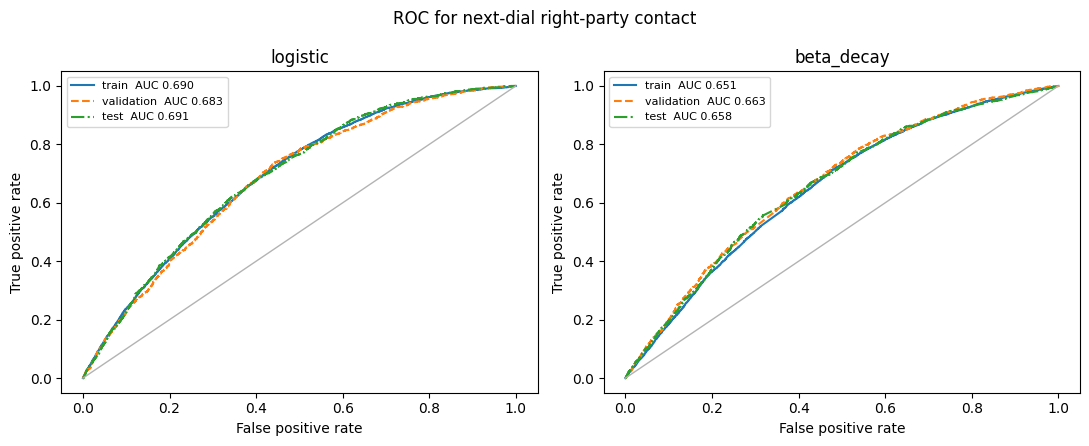

Confusion matrices at the validation Youden threshold

 logistic threshold 0.159
train
          pred_0  pred_1
actual_0   16076   13886
actual_1    1498    4355
validation
          pred_0  pred_1
actual_0    3690    2951
actual_1     318     900
test
          pred_0  pred_1
actual_0    3244    2858
actual_1     341     964

 beta_decay threshold 0.13
train
          pred_0  pred_1
actual_0   13465   16497
actual_1    1306    4547
validation
          pred_0  pred_1
actual_0    3078    3563
actual_1     263     955
test
          pred_0  pred_1
actual_0    2719    3383
actual_1     285    1020


In [7]:
op = metrics.loc[metrics["threshold_rule"].eq("validation_youden"), show_cols]
display(op.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, model, col in zip(axes, ["logistic", "beta_decay"], ["p_logit", "p_beta"]):
    for split, style in zip(SPLIT_ORDER, ["-", "--", "-."]):
        part = frame.loc[frame["split"].eq(split)]
        fpr, tpr, _ = roc_curve(part["y_rpc"], part[col])
        auc = roc_auc_score(part["y_rpc"], part[col])
        ax.plot(fpr, tpr, linestyle=style, label=f"{split}  AUC {auc:.3f}")
    ax.plot([0, 1], [0, 1], color="0.7", linewidth=1)
    ax.set_title(model)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(fontsize=8)
fig.suptitle("ROC for next-dial right-party contact")
fig.tight_layout()
fig.savefig(FIG / "roc_rpc_by_split.png", dpi=120, bbox_inches="tight")
plt.show()

print("Confusion matrices at the validation Youden threshold")
for model, col in [("logistic", "p_logit"), ("beta_decay", "p_beta")]:
    print("\n", model, "threshold", round(thresholds[model], 3))
    for split in SPLIT_ORDER:
        part = frame.loc[frame["split"].eq(split)]
        pred = (part[col] >= thresholds[model]).astype(int)
        cm = confusion_matrix(part["y_rpc"], pred, labels=[0, 1])
        print(split)
        print(pd.DataFrame(cm, index=["actual_0", "actual_1"], columns=["pred_0", "pred_1"]))

## 6. Verified phones: does the HMM rank borrower numbers?

The label is 1 when `verified_status` is `borrower_number`. The score is `p_borrower_number` from the hidden Markov filter (reachable plus avoiding). The operating threshold is Youden's J on the **train** gold phones only. Test has 36 verified phones, so the test ROC is a check, not a precise AUC.

verified_status  borrower_number  invalid_number  not_borrower_number  switched_off  third_party_number
split                                                                                                  
test                          16               0                    6             3                  11
train                         88               3                   19            14                  49
validation                    23               0                    2             2                  14
train-gold Youden threshold on P(borrower number): 0.703
            model       split     threshold_rule    n  positives  threshold  roc_auc  average_precision  accuracy  majority_accuracy  balanced_accuracy  precision  recall      f1   brier
0  hmm_p_borrower       train     threshold_0.50  173         88     0.5000   0.9034             0.9278    0.8382             0.5087             0.8377     0.8261  0.8636  0.8444  0.1282
1  hmm_p_borrower       train  train_gold_youden 

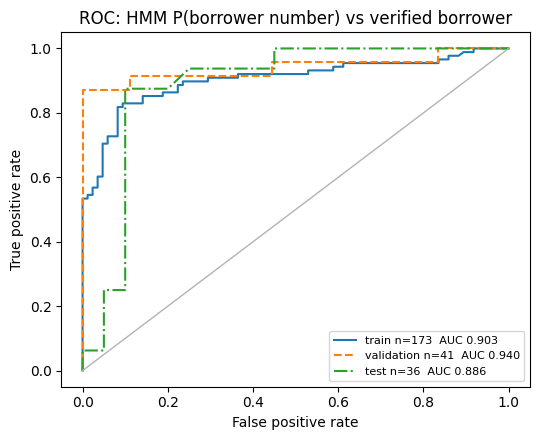

Coarse state accuracy (argmax HMM state vs verified status)
  train: accuracy 0.769 on 173 phones
  validation: accuracy 0.878 on 41 phones
  test: accuracy 0.778 on 36 phones

Test confusion, coarse state
hmm_coarse         borrower  off_long_term  recycled_or_wrong  temp_unreachable  third_party
gold_coarse                                                                                 
borrower                 14              0                  0                 1            1
off_long_term             0              3                  0                 0            0
recycled_or_wrong         4              0                  2                 0            0
third_party               1              0                  1                 0            9


In [8]:
GOLD_POSITIVE = "borrower_number"
gold = verified.merge(splits, on="account_id", how="left").merge(
    cp_scores[["account_id", "phone_id", "p_borrower_number", "p_state_valid_reachable", "p_suppress", "hmm_state", "was_dialled"]],
    on=["account_id", "phone_id"], how="left", validate="one_to_one",
)
gold["y_borrower"] = gold["verified_status"].eq(GOLD_POSITIVE).astype(int)
print(gold.groupby("split")["verified_status"].value_counts().unstack(fill_value=0))

train_gold = gold.loc[gold["split"].eq("train")]
gold_threshold = youden_threshold(train_gold["y_borrower"], train_gold["p_borrower_number"])
print("train-gold Youden threshold on P(borrower number):", round(gold_threshold, 3))

gold_rows = []
for split in SPLIT_ORDER:
    part = gold.loc[gold["split"].eq(split)]
    for rule, t in [("threshold_0.50", 0.5), ("train_gold_youden", gold_threshold)]:
        rec = binary_metrics(part["y_borrower"], part["p_borrower_number"], t)
        rec.update({"task": "gold_borrower_number", "model": "hmm_p_borrower", "split": split, "threshold_rule": rule})
        gold_rows.append(rec)
gold_metrics = pd.DataFrame(gold_rows)
display(gold_metrics.loc[:, show_cols].round(4))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for split, style in zip(SPLIT_ORDER, ["-", "--", "-."]):
    part = gold.loc[gold["split"].eq(split)]
    if part["y_borrower"].nunique() < 2:
        continue
    fpr, tpr, _ = roc_curve(part["y_borrower"], part["p_borrower_number"])
    auc = roc_auc_score(part["y_borrower"], part["p_borrower_number"])
    ax.plot(fpr, tpr, linestyle=style, label=f"{split} n={len(part)}  AUC {auc:.3f}")
ax.plot([0, 1], [0, 1], color="0.7", linewidth=1)
ax.set_title("ROC: HMM P(borrower number) vs verified borrower")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "roc_gold_borrower_by_split.png", dpi=120, bbox_inches="tight")
plt.show()

COARSE = {
    "borrower_number": "borrower",
    "third_party_number": "third_party",
    "not_borrower_number": "recycled_or_wrong",
    "switched_off": "off_long_term",
    "invalid_number": "invalid",
}
HMM_COARSE = {
    "valid_reachable": "borrower",
    "valid_avoiding": "borrower",
    "temp_unreachable": "temp_unreachable",
    "off_long_term": "off_long_term",
    "third_party": "third_party",
    "recycled_or_wrong": "recycled_or_wrong",
    "invalid": "invalid",
}
gold["gold_coarse"] = gold["verified_status"].map(COARSE)
gold["hmm_coarse"] = gold["hmm_state"].map(HMM_COARSE)
print("Coarse state accuracy (argmax HMM state vs verified status)")
for split in SPLIT_ORDER:
    part = gold.loc[gold["split"].eq(split)]
    acc = float((part["gold_coarse"] == part["hmm_coarse"]).mean())
    print(f"  {split}: accuracy {acc:.3f} on {len(part)} phones")
print("\nTest confusion, coarse state")
test_gold = gold.loc[gold["split"].eq("test")]
display(pd.crosstab(test_gold["gold_coarse"], test_gold["hmm_coarse"], dropna=False))

## 7. Payment within 14 days of a right-party contact

The label exists only for accounts with an RPC whose 14-day follow-up finished inside the data window. Train metrics are in-sample. Validation and test are the held-out reads. The threshold is Youden's J on validation accounts.

validation Youden threshold: 0.45
               n  keep_rate
split                      
test         311      0.482
train       1446      0.497
validation   305      0.462
            model       split     threshold_rule     n  positives  threshold  roc_auc  average_precision  accuracy  majority_accuracy  balanced_accuracy  precision  recall      f1   brier
0  logistic_repay       train     threshold_0.50  1446        718     0.5000   0.6466             0.6392    0.6079             0.5035             0.6078     0.6074  0.5947  0.6010  0.2334
1  logistic_repay       train  validation_youden  1446        718     0.4499   0.6466             0.6392    0.5913             0.5035             0.5921     0.5705  0.7159  0.6350  0.2334
2  logistic_repay  validation     threshold_0.50   305        141     0.5000   0.6040             0.5902    0.5672             0.5377             0.5732     0.5257  0.6525  0.5823  0.2428
3  logistic_repay  validation  validation_youden   305        141     0.44

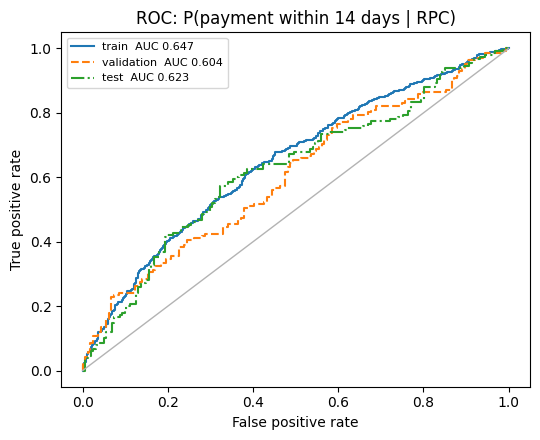

In [9]:
repay = acct_scores.loc[acct_scores["y_repay"].notna(), ["account_id", "split", "y_repay", "p_repay_if_reached"]].copy()
repay["y_repay"] = repay["y_repay"].astype(int)
val_repay = repay.loc[repay["split"].eq("validation")]
repay_threshold = youden_threshold(val_repay["y_repay"], val_repay["p_repay_if_reached"])
print("validation Youden threshold:", round(repay_threshold, 3))
print(repay.groupby("split")["y_repay"].agg(["size", "mean"]).rename(columns={"size": "n", "mean": "keep_rate"}).round(3))

repay_rows = []
for split in SPLIT_ORDER:
    part = repay.loc[repay["split"].eq(split)]
    for rule, t in [("threshold_0.50", 0.5), ("validation_youden", repay_threshold)]:
        rec = binary_metrics(part["y_repay"], part["p_repay_if_reached"], t)
        rec.update({"task": "pay_within_14d_given_rpc", "model": "logistic_repay", "split": split, "threshold_rule": rule})
        repay_rows.append(rec)
repay_metrics = pd.DataFrame(repay_rows)
display(repay_metrics.loc[:, show_cols].round(4))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for split, style in zip(SPLIT_ORDER, ["-", "--", "-."]):
    part = repay.loc[repay["split"].eq(split)]
    fpr, tpr, _ = roc_curve(part["y_repay"], part["p_repay_if_reached"])
    auc = roc_auc_score(part["y_repay"], part["p_repay_if_reached"])
    ax.plot(fpr, tpr, linestyle=style, label=f"{split}  AUC {auc:.3f}")
ax.plot([0, 1], [0, 1], color="0.7", linewidth=1)
ax.set_title("ROC: P(payment within 14 days | RPC)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "roc_repay_by_split.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Saved tables

`outputs/metrics_by_split.csv` stacks the three tasks. Read `roc_auc` for ranking and `balanced_accuracy` for a class prediction. Compare `accuracy` with `majority_accuracy` on the same row.

In [10]:
all_metrics = pd.concat([metrics, gold_metrics, repay_metrics], ignore_index=True)
front = ["task", "model", "split", "threshold_rule"]
ordered = front + [c for c in all_metrics.columns if c not in front]
all_metrics = all_metrics[ordered]
all_metrics.to_csv(OUT / "metrics_by_split.csv", index=False)
print("wrote", OUT / "metrics_by_split.csv")
headline = all_metrics.loc[
    all_metrics["threshold_rule"].isin(["validation_youden", "train_gold_youden"]),
    ["task", "model", "split", "n", "roc_auc", "accuracy", "majority_accuracy", "balanced_accuracy", "recall", "precision", "brier"],
]
display(headline.round(4))

wrote /Users/adityagupta/Documents/OPEN_IIT/OPEN_IIT_PS2/outputs/metrics_by_split.csv
                        task           model       split      n  roc_auc  accuracy  majority_accuracy  balanced_accuracy  recall  precision   brier
1              next_dial_rpc        constant       train  35815   0.5000    0.8366             0.8366             0.5000  0.0000     0.0000  0.1367
3              next_dial_rpc        constant  validation   7859   0.5000    0.8450             0.8450             0.5000  0.0000     0.0000  0.1310
5              next_dial_rpc        constant        test   7407   0.5000    0.8238             0.8238             0.5000  0.0000     0.0000  0.1453
7              next_dial_rpc      beta_decay       train  35815   0.6512    0.5029             0.8366             0.6131  0.7769     0.2161  0.1324
9              next_dial_rpc      beta_decay  validation   7859   0.6635    0.5132             0.8450             0.6238  0.7841     0.2114  0.1260
11             next_dial_r